## Model 3 : Failure Risk prediction

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import joblib


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import RandomOverSampler

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

### Load dataset

In [6]:
df = pd.read_csv("../dataset/ev_battery_health.csv")

In [7]:
df.head()

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


In [8]:
df.shape

(50000, 35)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  object 
 1   observation_id                  50000 non-null  object 
 2   chemistry                       46541 non-null  object 
 3   manufacturer                    47539 non-null  object 
 4   vehicle_model                   46485 non-null  object 
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  object 
 7   observation_date                47784 non-null  object 
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  object 
 11  avg_daily_distance_km           47882 non-null  float64
 12  avg_charging_power_kw           

In [10]:
df.describe().round(0)

,pack_capacity_kwh,battery_age_days,cycle_count,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,avg_depth_of_discharge_pct,avg_state_of_charge_pct,charge_cycles_per_month,total_energy_throughput_kwh,...,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,recall_flag,state_of_health_pct,remaining_useful_life_cycles
count,47698.0,46998.0,47731.0,47882.0,47860.0,46595.0,47168.0,46862.0,47946.0,46630.0,...,47896.0,47193.0,47513.0,47909.0,47872.0,48131.0,48400.0,47354.0,50000.0,50000.0
mean,73.0,561.0,571.0,50.0,32.0,0.0,65.0,68.0,20.0,38510.0,...,49.0,364.0,138.0,126.0,27.0,7.0,1.0,0.0,93.0,1491.0
std,14.0,480.0,600.0,39.0,18.0,0.0,16.0,10.0,10.0,42274.0,...,21.0,12.0,20.0,109.0,13.0,7.0,2.0,0.0,7.0,1214.0
min,40.0,1.0,1.0,3.0,1.0,0.0,10.0,31.0,2.0,36.0,...,8.0,318.0,25.0,5.0,-11.0,0.0,0.0,0.0,55.0,0.0
25%,62.0,169.0,137.0,22.0,19.0,0.0,54.0,61.0,13.0,8858.0,...,35.0,355.0,125.0,61.0,18.0,2.0,0.0,0.0,90.0,600.0
50%,73.0,424.0,371.0,39.0,29.0,0.0,65.0,68.0,19.0,24134.0,...,43.0,366.0,137.0,94.0,27.0,5.0,1.0,0.0,95.0,1142.0
75%,83.0,846.0,801.0,66.0,42.0,0.0,76.0,75.0,26.0,53339.0,...,57.0,373.0,150.0,150.0,36.0,10.0,2.0,0.0,98.0,2322.0
max,100.0,2184.0,5073.0,400.0,160.0,1.0,100.0,95.0,58.0,402420.0,...,307.0,403.0,292.0,1232.0,94.0,45.0,15.0,1.0,100.0,5928.0


### Remove unnecessary columns

In [11]:
df.columns

Index(['battery_id', 'observation_id', 'chemistry', 'manufacturer',
       'vehicle_model', 'pack_capacity_kwh', 'manufacture_date',
       'observation_date', 'battery_age_days', 'cycle_count', 'climate_zone',
       'avg_daily_distance_km', 'avg_charging_power_kw', 'fast_charge_ratio',
       'avg_depth_of_discharge_pct', 'avg_state_of_charge_pct',
       'charge_cycles_per_month', 'total_energy_throughput_kwh',
       'avg_ambient_temp_c', 'humidity_pct', 'altitude_m',
       'internal_resistance_mohm', 'voltage_avg_v', 'current_avg_a',
       'charge_time_avg_min', 'peak_temp_during_fast_charge_c',
       'capacity_fade_pct', 'service_count', 'last_service_date',
       'bms_firmware_version', 'recall_flag', 'state_of_health_pct',
       'remaining_useful_life_cycles', 'failure_risk_label',
       'degradation_category'],
      dtype='object')

In [12]:
drop_columns = ["battery_id", "observation_id","manufacture_date", "observation_date", "last_service_date",
                "capacity_fade_pct", "state_of_health_pct", "remaining_useful_life_cycles", "degradation_category"]

df = df.drop(drop_columns, axis=1)
df.shape

(50000, 26)

### Remove duplicate rows

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df=df.drop_duplicates()
df.shape

(50000, 26)

### Missing values

In [15]:
df.isnull().sum()

chemistry                         3459
manufacturer                      2461
vehicle_model                     3515
pack_capacity_kwh                 2302
battery_age_days                  3002
cycle_count                       2269
climate_zone                      2719
avg_daily_distance_km             2118
avg_charging_power_kw             2140
fast_charge_ratio                 3405
avg_depth_of_discharge_pct        2832
avg_state_of_charge_pct           3138
charge_cycles_per_month           2054
total_energy_throughput_kwh       3370
avg_ambient_temp_c                3282
humidity_pct                      2737
altitude_m                        2322
internal_resistance_mohm          2104
voltage_avg_v                     2807
current_avg_a                     2487
charge_time_avg_min               2091
peak_temp_during_fast_charge_c    2128
service_count                     1600
bms_firmware_version              2328
recall_flag                       2646
failure_risk_label       

In [16]:
# numeric columns -> fill with median
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# text columns -> fill with most common value (mode)
cat_cols = df.select_dtypes(exclude="number").columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [17]:
df.isnull().sum()

chemistry                         0
manufacturer                      0
vehicle_model                     0
pack_capacity_kwh                 0
battery_age_days                  0
cycle_count                       0
climate_zone                      0
avg_daily_distance_km             0
avg_charging_power_kw             0
fast_charge_ratio                 0
avg_depth_of_discharge_pct        0
avg_state_of_charge_pct           0
charge_cycles_per_month           0
total_energy_throughput_kwh       0
avg_ambient_temp_c                0
humidity_pct                      0
altitude_m                        0
internal_resistance_mohm          0
voltage_avg_v                     0
current_avg_a                     0
charge_time_avg_min               0
peak_temp_during_fast_charge_c    0
service_count                     0
bms_firmware_version              0
recall_flag                       0
failure_risk_label                0
dtype: int64

### Outlier analysis

In [18]:
# numeric input columns (skip the target and 0/1 columns)
outlier_cols = [col for col in num_cols if col != "failure_risk_label" and df[col].nunique() > 2]
len(outlier_cols)

19

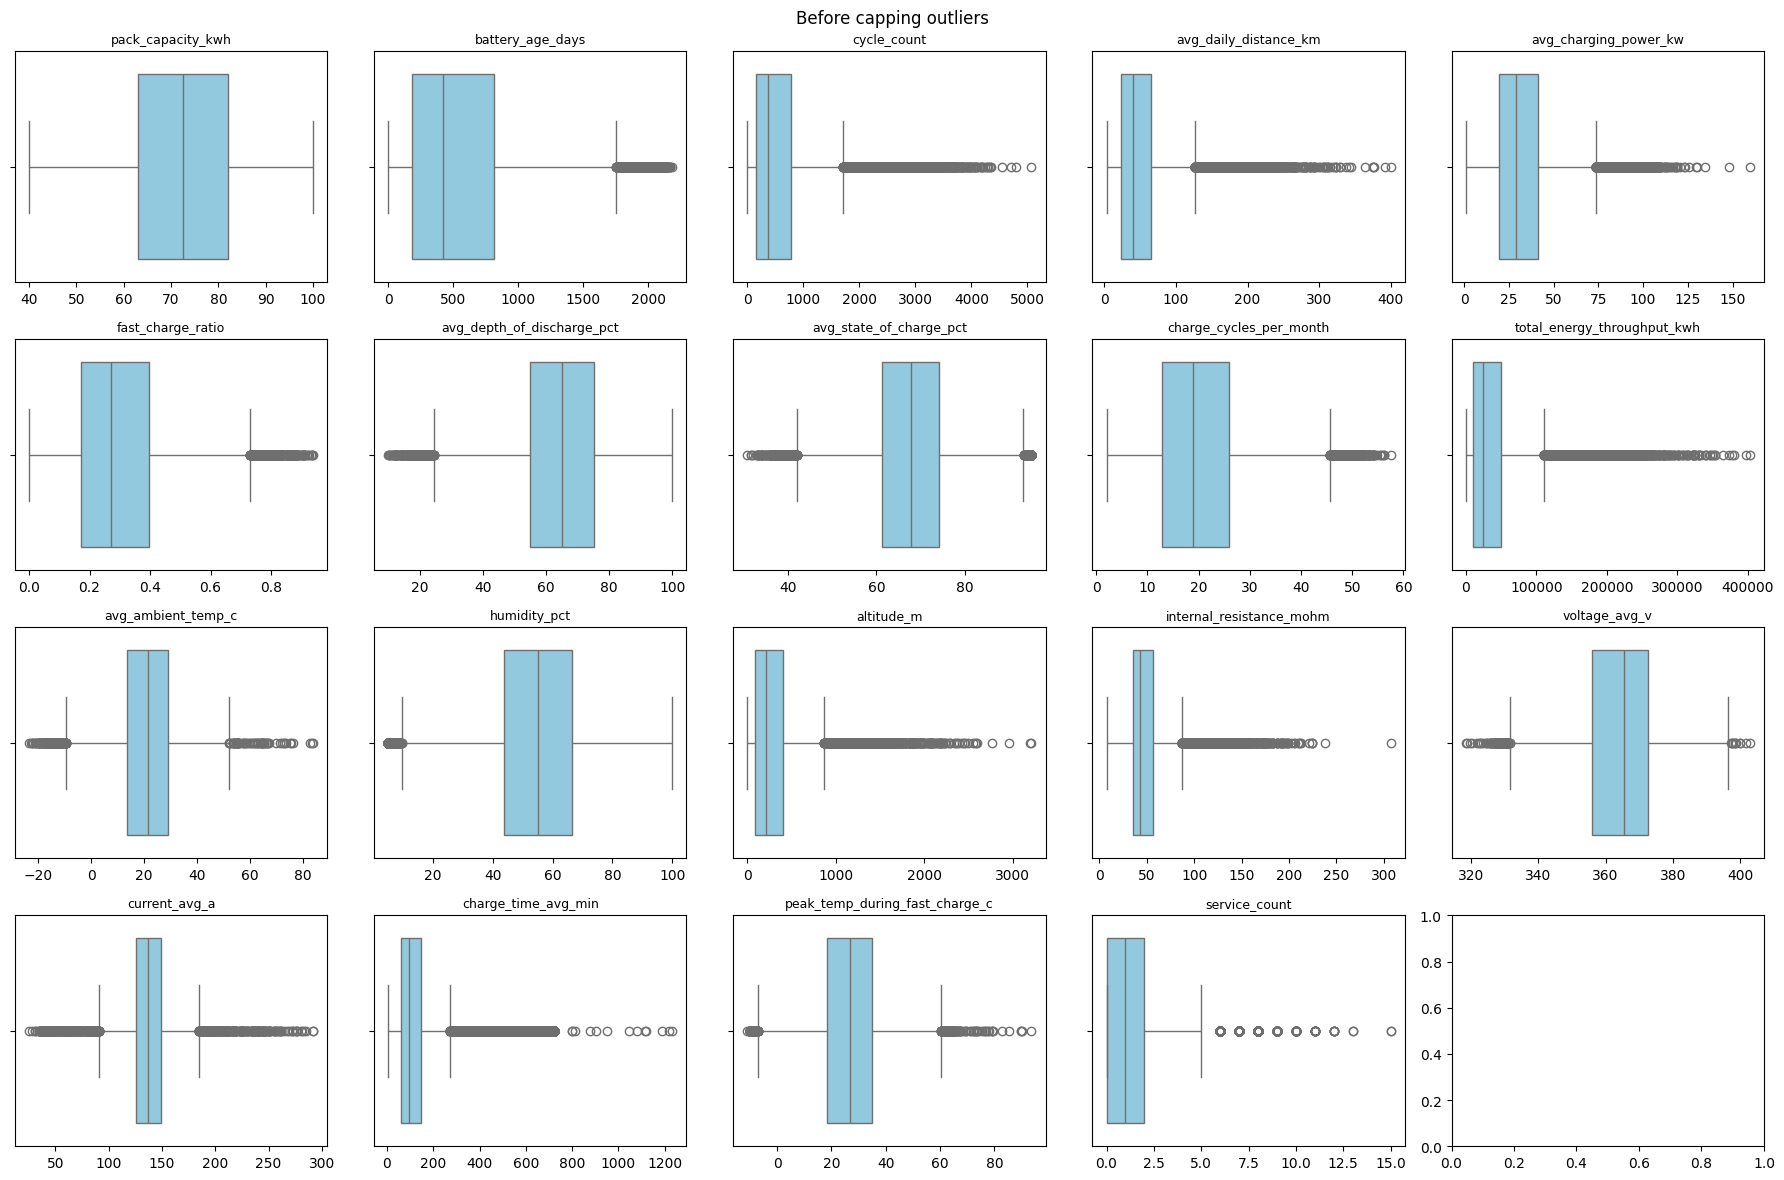

In [19]:
# boxplots before capping
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color="skyblue")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Before capping outliers")
plt.tight_layout()
plt.show()

In [20]:
# count outliers and cap them
for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:32s} outliers = {outliers}")
    df[col] = df[col].clip(lower, upper)

pack_capacity_kwh                outliers = 0
battery_age_days                 outliers = 1015
cycle_count                      outliers = 2757
avg_daily_distance_km            outliers = 2499
avg_charging_power_kw            outliers = 1436
fast_charge_ratio                outliers = 552
avg_depth_of_discharge_pct       outliers = 265
avg_state_of_charge_pct          outliers = 506
charge_cycles_per_month          outliers = 660
total_energy_throughput_kwh      outliers = 3107
avg_ambient_temp_c               outliers = 410
humidity_pct                     outliers = 283
altitude_m                       outliers = 2641
internal_resistance_mohm         outliers = 2940
voltage_avg_v                    outliers = 161
current_avg_a                    outliers = 894
charge_time_avg_min              outliers = 3585
peak_temp_during_fast_charge_c   outliers = 322
service_count                    outliers = 1520


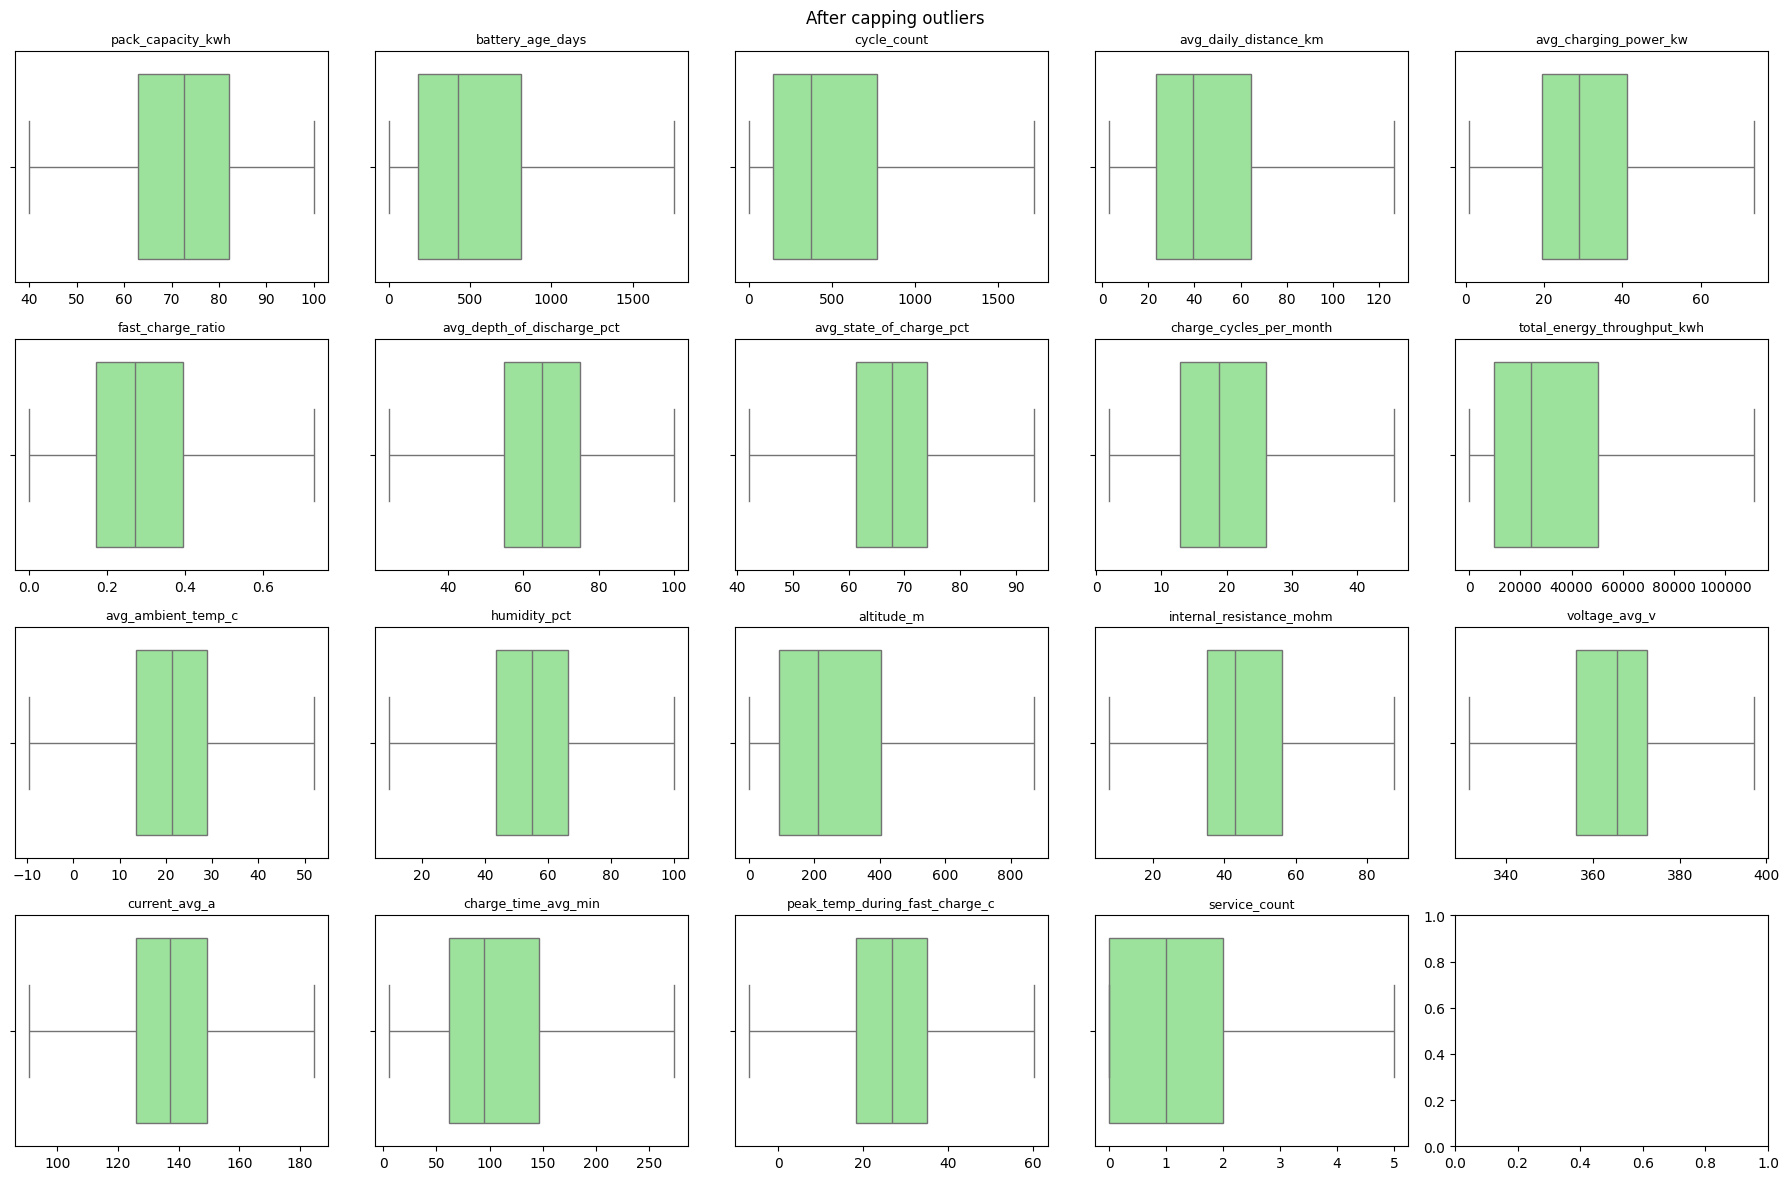

In [21]:
# boxplots after capping
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color="lightgreen")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("After capping outliers")
plt.tight_layout()
plt.show()

### EDA (Exploratory Data Analysis)

In [22]:
df["failure_risk_label"].value_counts()   # classes are imbalanced (most are Low)

failure_risk_label
Low       42735
Medium     4409
High       2856
Name: count, dtype: int64

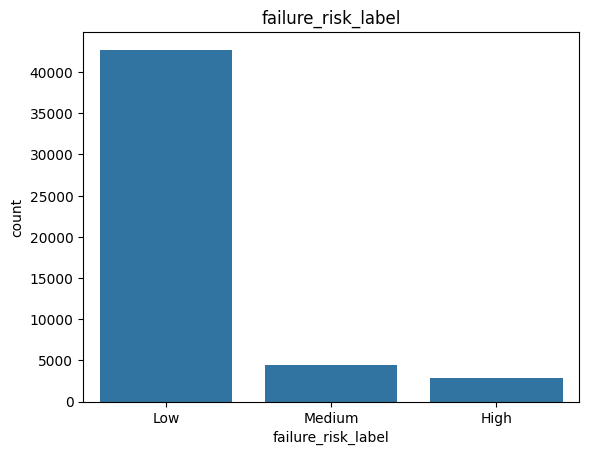

In [23]:
sns.countplot(x=df["failure_risk_label"], order=["Low", "Medium", "High"])
plt.title("failure_risk_label")
plt.show()

In [24]:
co = df.corr(numeric_only=True)   # correlation between numeric columns

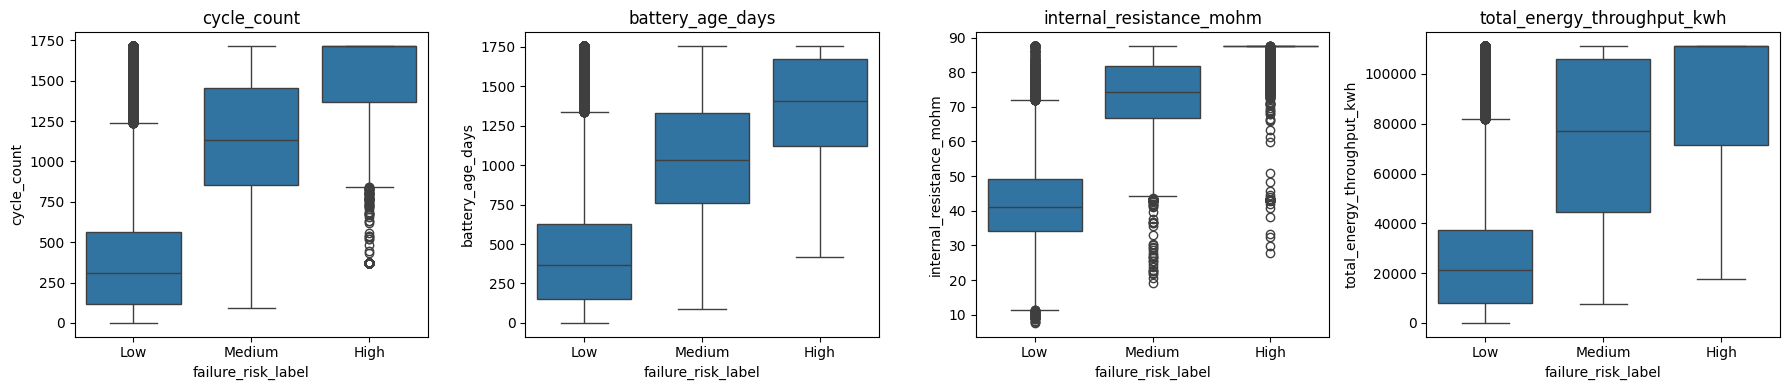

In [25]:
# compare important columns between the risk groups
features = ["cycle_count", "battery_age_days", "internal_resistance_mohm", "total_energy_throughput_kwh"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(x=df["failure_risk_label"], y=df[col], order=["Low", "Medium", "High"], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Encode text columns

In [26]:
cat_cols = cat_cols.drop("failure_risk_label")   # the target stays as text (Low / Medium / High)
cat_cols

Index(['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone',
       'bms_firmware_version'],
      dtype='object')

In [27]:
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le   # keep the encoder so new data can be encoded the same way

In [28]:
df.head()

,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,battery_age_days,cycle_count,climate_zone,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,...,altitude_m,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,peak_temp_during_fast_charge_c,service_count,bms_firmware_version,recall_flag,failure_risk_label
0,1,6,1,48.5,693.0,991.0,0,120.3,28.8,0.345,...,390.0,87.52,365.6,146.4,40.1,-1.3,4.0,0,0.0,High
1,0,7,5,61.5,662.0,1535.0,0,93.4,73.5,0.569,...,871.0,49.95,357.3,176.0,38.0,5.3,0.0,3,0.0,Low
2,0,3,7,73.1,424.0,407.0,0,45.0,73.5,0.641,...,249.0,37.90,375.4,156.8,41.7,21.3,0.0,2,0.0,Low
3,3,0,7,75.6,33.0,29.0,0,42.4,73.5,0.596,...,3.0,43.08,361.7,150.3,18.2,20.8,0.0,4,0.0,Low
4,2,7,2,92.7,520.0,324.0,1,23.4,36.3,0.550,...,206.0,68.34,374.0,159.5,79.2,40.1,0.0,0,0.0,Low


### Splitting into train and test

In [29]:
x = df.drop(["failure_risk_label"], axis=1)
y = df["failure_risk_label"]


In [30]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print("Training rows :", len(x_train))
print("Test rows :", len(x_test))

Training rows : 40000
Test rows : 10000


### Scaling

In [31]:
scaler = StandardScaler()

In [32]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

## CLASS IMBALANCE HANDLING
#### Random Over Sampling

In [33]:
print("\nBefore Oversampling:")
print(y_train.value_counts())



Before Oversampling:
failure_risk_label
Low       34188
Medium     3527
High       2285
Name: count, dtype: int64


In [34]:
# Create RandomOverSampler

ros = RandomOverSampler(random_state=42)


# Apply only to training data

x_train, y_train = ros.fit_resample(
    x_train,
    y_train
)


print("\nAfter Oversampling:")
print(y_train.value_counts())


After Oversampling:
failure_risk_label
Low       34188
Medium    34188
High      34188
Name: count, dtype: int64


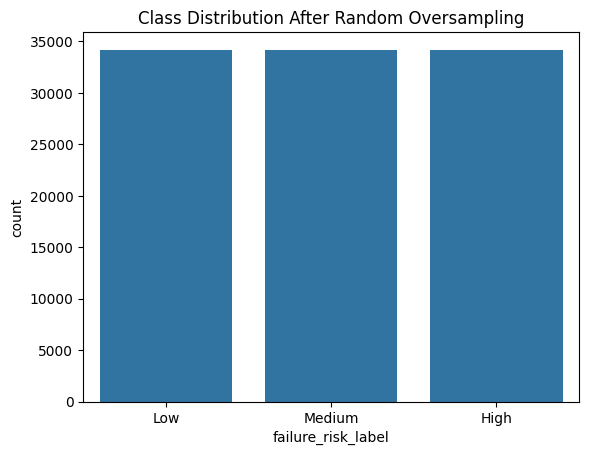

In [35]:

sns.countplot(
    x=y_train,
    order=["Low", "Medium", "High"]
)

plt.title("Class Distribution After Random Oversampling")
plt.show()


### Train the models

In [36]:
results = []   # we store the score of every model here
models = {}    # and the trained models here

#### 1. Logistic Regression


In [37]:
log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(x_train, y_train)
y_pred_log = log_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log, average="macro")
train_accuracy = log_model.score(x_train, y_train)

print(f"accuracy = {accuracy:.3f}  f1 score = {f1:.3f}")
print(f"Train accuracy = {train_accuracy:.3f}  Test accuracy = {accuracy:.3f}")

results.append(["Logistic Regression", train_accuracy, accuracy, f1])
models["Logistic Regression"] = log_model

accuracy = 0.875  f1 score = 0.740
Train accuracy = 0.823  Test accuracy = 0.875


#### 2. Decision Tree

In [38]:
dt_model = DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42)
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_dt)
f1 = f1_score(y_test, y_pred_dt, average="macro")
train_accuracy = dt_model.score(x_train, y_train)

print(f"accuracy = {accuracy:.3f}  f1 score = {f1:.3f}")
print(f"Train accuracy = {train_accuracy:.3f}  Test accuracy = {accuracy:.3f}")

results.append(["Decision Tree", train_accuracy, accuracy, f1])
models["Decision Tree"] = dt_model

accuracy = 0.914  f1 score = 0.787
Train accuracy = 0.966  Test accuracy = 0.914


#### 3. Random Forest

In [39]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight="balanced", n_jobs=-1, random_state=42)
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf, average="macro")
train_accuracy = rf_model.score(x_train, y_train)

print(f"accuracy = {accuracy:.3f}  f1 score = {f1:.3f}")
print(f"Train accuracy = {train_accuracy:.3f}  Test accuracy = {accuracy:.3f}")

results.append(["Random Forest", train_accuracy, accuracy, f1])
models["Random Forest"] = rf_model

accuracy = 0.938  f1 score = 0.840
Train accuracy = 0.991  Test accuracy = 0.938


#### 4. Gradient Boosting

In [40]:
gb_model = GradientBoostingClassifier(n_estimators=200, random_state=42)
gb_model.fit(x_train, y_train)
y_pred_gb = gb_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred_gb)
f1 = f1_score(y_test, y_pred_gb, average="macro")
train_accuracy = gb_model.score(x_train, y_train)

print(f"accuracy = {accuracy:.3f}  f1 score = {f1:.3f}")
print(f"Train accuracy = {train_accuracy:.3f}  Test accuracy = {accuracy:.3f}")

results.append(["Gradient Boosting", train_accuracy, accuracy, f1])
models["Gradient Boosting"] = gb_model

accuracy = 0.925  f1 score = 0.836
Train accuracy = 0.931  Test accuracy = 0.925


### Compare the models
#### About 85% of batteries are Low risk, so a model that always says "Low" already gets 85% accuracy.
#### That is why we pick the best model by f1 score (it checks Low, Medium and High equally), and also show accuracy.



In [41]:
compare = pd.DataFrame(results, columns=["model", "train_accuracy", "test_accuracy", "f1_score"])
compare = compare.sort_values("f1_score", ascending=False).round(3)
compare

,model,train_accuracy,test_accuracy,f1_score
2,Random Forest,0.991,0.938,0.840
3,Gradient Boosting,0.931,0.925,0.836
1,Decision Tree,0.966,0.914,0.787
0,Logistic Regression,0.823,0.875,0.740


In [42]:
best_name = compare.iloc[0]["model"]
best_model = models[best_name]
y_pred = best_model.predict(x_test)
print("Best model :", best_name)

Best model : Random Forest


### Evaluation of the best model

In [43]:
labels = ["Low", "Medium", "High"]
print("confusion matrix :\n", confusion_matrix(y_test, y_pred, labels=labels))
print(classification_report(y_test, y_pred, labels=labels))

confusion matrix :
 [[8183  361    3]
 [  96  733   53]
 [   3  109  459]]
              precision    recall  f1-score   support

         Low       0.99      0.96      0.97      8547
      Medium       0.61      0.83      0.70       882
        High       0.89      0.80      0.85       571

    accuracy                           0.94     10000
   macro avg       0.83      0.86      0.84     10000
weighted avg       0.95      0.94      0.94     10000



### Save the best model

In [44]:
saved = {
    "model": models["Gradient Boosting"],
    "scaler": scaler,
    "encoders": encoders,
    "columns": list(x.columns),
}
joblib.dump(saved, "../models/failure_risk_model.pkl", compress=3)
print("Saved : models/failure_risk_model.pkl")

Saved : models/failure_risk_model.pkl


### Test the saved model

In [45]:
loaded = joblib.load("../models/failure_risk_model.pkl")
model = loaded["model"]

y_new = model.predict(x_test[0:5])   # predict the first 5 test rows
print("Predicted :", y_new)
print("Actual    :", np.array(y_test[0:5]))

Predicted : ['Low' 'Low' 'Low' 'Low' 'Low']
Actual    : ['Low' 'Low' 'Low' 'Low' 'Low']
